In [2]:
!pip install numpy pandas matplotlib seaborn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Employee.csv")

In [4]:
df

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0
...,...,...,...,...,...,...
143,TCS,33.0,9024.0,Calcutta,India,1
144,Infosys,22.0,8787.0,Calcutta,India,1
145,Infosys,44.0,4034.0,Delhi,India,1
146,TCS,33.0,5034.0,Mumbai,India,1


In [5]:
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (148, 6)


,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    str    
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    str    
 4   Country  148 non-null    str    
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 7.1 KB


In [6]:
df.isna().sum()

Company     8
Age        18
Salary     24
Place      14
Country     0
Gender      0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 4
Shape after removing duplicates: (144, 6)


In [8]:
df.info()

<class 'pandas.DataFrame'>
Index: 144 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  136 non-null    str    
 1   Age      127 non-null    float64
 2   Salary   121 non-null    float64
 3   Place    130 non-null    str    
 4   Country  144 non-null    str    
 5   Gender   144 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 7.9 KB


In [12]:
df.replace({'Company': {
    'Infosys Pvt Lmt': 'Infosys',
    'Tata Consultancy Services': 'TCS',
    'CTS': 'Cognizant',
    'Congnizant': 'Cognizant'
}}, inplace=True)

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0
...,...,...,...,...,...,...
142,Infosys,22.0,8202.0,Mumbai,India,0
143,TCS,33.0,9024.0,Calcutta,India,1
145,Infosys,44.0,4034.0,Delhi,India,1
146,TCS,33.0,5034.0,Mumbai,India,1


In [13]:
# Correct way - Option 1 (using df.replace)
df.replace({'Place': {'Podicherry': 'Pondicherry'}}, inplace=True)

# Or Option 2 (assign back to column)
df['Place'] = df['Place'].replace('Podicherry', 'Pondicherry')

# Now check unique values (no warning)
df['Place'].unique()

<StringArray>
[    'Chennai',      'Mumbai',    'Calcutta',       'Delhi', 'Pondicherry',
      'Cochin',           nan,       'Noida',   'Hyderabad',      'Bhopal',
      'Nagpur',        'Pune']
Length: 12, dtype: str

In [14]:
df['Company'].isna().sum()

np.int64(8)

In [15]:
df['Company'] = df['Company'].fillna(df['Company'].mode()[0])
df['Company'].isna().sum()

np.int64(0)

In [16]:
df[df['Age'] == 0]

,Company,Age,Salary,Place,Country,Gender
88,Infosys,0.0,3030.0,Calcutta,India,0
92,TCS,0.0,3045.0,Delhi,India,0
101,Cognizant,0.0,2034.0,Pondicherry,India,0
107,TCS,0.0,9024.0,Chennai,India,1
111,Infosys,0.0,3234.0,Mumbai,India,0
121,Cognizant,0.0,1234.0,Calcutta,India,0


In [17]:
df['Age'] = df['Age'].replace(0, np.nan)

In [18]:
mean_salary = round(df['Salary'].mean())
print("Mean Salary:", mean_salary)
df['Salary'] = df['Salary'].fillna(mean_salary)

Mean Salary: 5283


In [19]:
df['Place'] = df['Place'].fillna(df['Place'].mode()[0])

In [20]:
df.isna().sum()

Company     0
Age        23
Salary      0
Place       0
Country     0
Gender      0
dtype: int64

In [21]:
df.head()

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,5283.0,Chennai,India,0
1,Infosys,30.0,5283.0,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


In [22]:
df.describe()

,Age,Salary,Gender
count,121.000000,144.000000,144.000000
mean,32.041322,5283.395833,0.222222
std,8.989250,2368.350171,0.417191
min,17.000000,1089.000000,0.000000
25%,23.000000,3045.000000,0.000000
50%,33.000000,5283.000000,0.000000
75%,40.000000,7084.000000,0.000000
max,54.000000,9876.000000,1.000000


In [23]:
Q1 = df['Age'].quantile(0.25)    # 22.0
Q3 = df['Age'].quantile(0.75)    # 37.75
IQR = Q3 - Q1                    # 15.75
lower = Q1 - 1.5 * IQR           # -1.625
upper = Q3 + 1.5 * IQR           # 61.375

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower)
print("Upper limit:", upper)

Q1: 23.0
Q3: 40.0
IQR: 17.0
Lower limit: -2.5
Upper limit: 65.5


In [24]:
salary_outliers = df[
    (df['Salary'] < lower) | 
    (df['Salary'] > upper)
]
salary_outliers

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,5283.0,Chennai,India,0
1,Infosys,30.0,5283.0,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0
...,...,...,...,...,...,...
142,Infosys,22.0,8202.0,Mumbai,India,0
143,TCS,33.0,9024.0,Calcutta,India,1
145,Infosys,44.0,4034.0,Delhi,India,1
146,TCS,33.0,5034.0,Mumbai,India,1


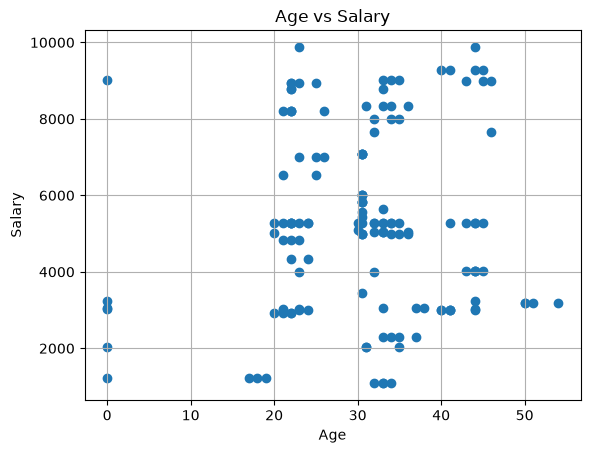

In [26]:
# Make sure data is clean first!
df = pd.read_csv("Employee.csv")
df.drop_duplicates(inplace=True)
df[['Age', 'Salary']] = df[['Age', 'Salary']].fillna(df[['Age', 'Salary']].mean())

# Then just use this one line:
plt.scatter(df['Age'], df['Salary']); plt.xlabel('Age'); plt.ylabel('Salary'); plt.title('Age vs Salary'); plt.grid(True); plt.show()

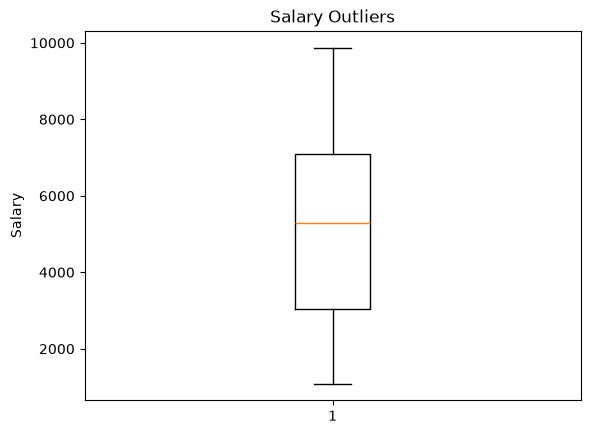

In [27]:
plt.boxplot(df['Salary'])
plt.ylabel("Salary")
plt.title("Salary Outliers")
plt.show()

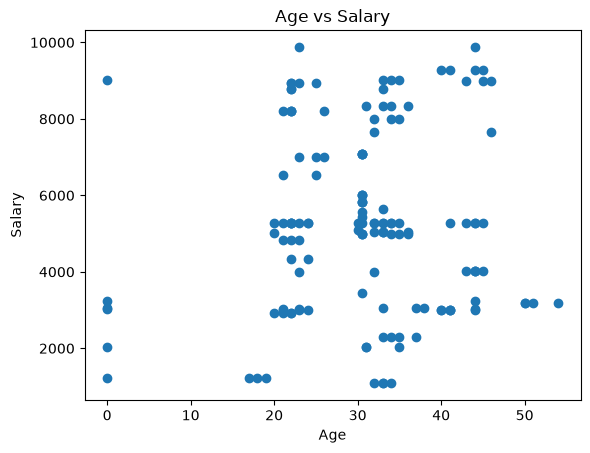

In [28]:
plt.scatter(df['Age'], df['Salary'])
plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Age vs Salary")
plt.show()

In [29]:
place_count = df['Place'].value_counts()
print(place_count)

Place
Mumbai        34
Calcutta      32
Chennai       14
Delhi         14
Cochin        13
Noida          8
Hyderabad      8
Podicherry     3
Pune           2
Bhopal         1
Nagpur         1
Name: count, dtype: int64


In [30]:
# Set pandas to show ALL rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Display the entire dataset
print(df)

                       Company        Age       Salary       Place Country  \
0                          TCS  20.000000  5283.471074     Chennai   India   
1                      Infosys  30.000000  5283.471074      Mumbai   India   
2                          TCS  35.000000  2300.000000    Calcutta   India   
3                      Infosys  40.000000  3000.000000       Delhi   India   
4                          TCS  23.000000  4000.000000      Mumbai   India   
5                      Infosys  30.527559  5000.000000    Calcutta   India   
6                          TCS  30.527559  6000.000000     Chennai   India   
7                      Infosys  23.000000  7000.000000      Mumbai   India   
8                          TCS  34.000000  8000.000000    Calcutta   India   
9                          CTS  45.000000  9000.000000       Delhi   India   
10                         CTS  23.000000  5283.471074      Mumbai   India   
11                         CTS  34.000000  1089.000000    Calcut